In [1]:
import numpy as np
import pandas as pd

In [2]:
def load_neighbours(modality, cell):
    frame = pd.read_csv(
        f"../../result/HEK293T_HCT116/input/{modality}-{cell}.ppi",
        sep="\t",
    )
    neighbours = {}
    for a, b in zip(frame["GeneA"], frame["GeneB"]):
        neighbours.setdefault(a, set()).add(b)
        neighbours.setdefault(b, set()).add(a)
    return neighbours


def raw_change(modality):
    nb_q = load_neighbours(modality, "HEK293T")
    nb_b = load_neighbours(modality, "HCT116")
    shared = set(nb_q) & set(nb_b)
    rows = []
    for gene in sorted(shared):
        sq = nb_q[gene] & shared
        sb = nb_b[gene] & shared
        union = len(sq | sb)
        rows.append({
            "gene": gene,
            "absdlogdeg": abs(np.log2((len(sq) + 1) / (len(sb) + 1))),
            "raw_jaccard": (1 - len(sq & sb) / union) if union else 0.0,
        })
    return pd.DataFrame(rows).set_index("gene")

raw = {m: raw_change(m) for m in ["BioPlex", "SECMX"]}

In [3]:
support = pd.read_csv(
    "../../result/HEK293T_HCT116/coemb/promergeclub_HEK293Tanchor/HCT116/HCT116_support.tsv",
    sep="\t",
    index_col=0,
)
names = pd.Index(sorted(support.index[support["base"] == 1]))

percentiles = pd.DataFrame({
    "AP-Degree": raw["BioPlex"]["absdlogdeg"],
    "AP-Jaccard": raw["BioPlex"]["raw_jaccard"],
    "SEC-Degree": raw["SECMX"]["absdlogdeg"],
    "SEC-Jaccard": raw["SECMX"]["raw_jaccard"],
}).reindex(names).rank(method="average", pct=True) * 100

table = percentiles.reindex(["HYCC2", "CIMIP5", "TXN2", "TTC7B"])
table.index.name = "Gene"

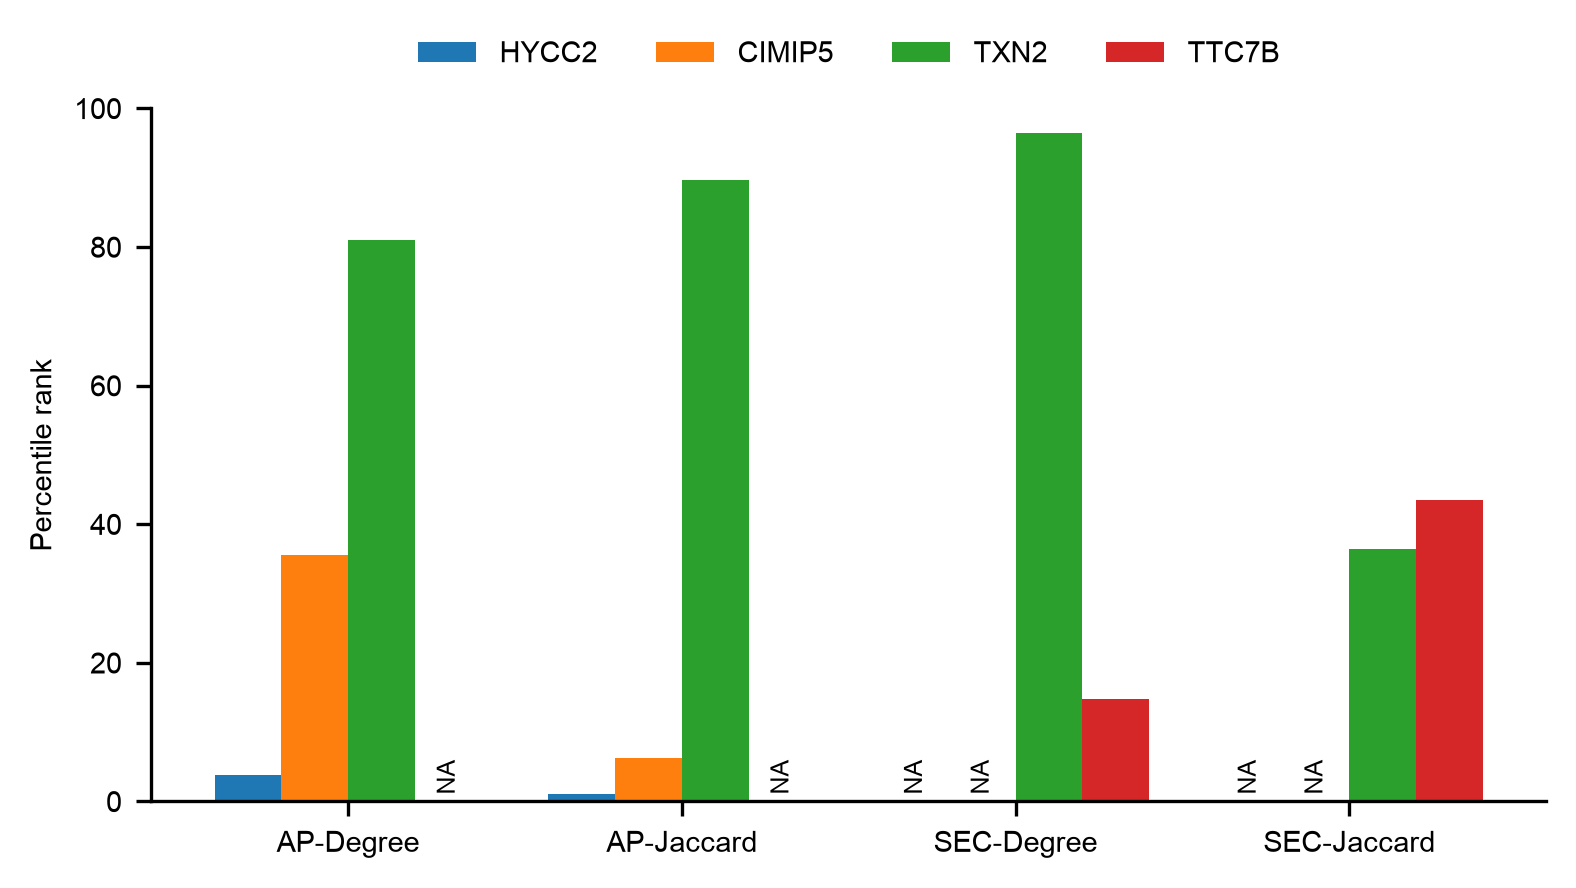

In [4]:
import sys
import matplotlib.pyplot as plt

if sys.platform == "darwin":
    plt.style.use("/Users/jhgao/misc/style.mplstyle")
else:
    plt.style.use("/home/jig049/misc/style.mplstyle")

fig, ax = plt.subplots(figsize=(6, 3), dpi=300)
for index, (gene, values) in enumerate(table.iterrows()):
    positions = (
        np.arange(len(table.columns))
        + (index - (len(table) - 1) / 2) * 0.8 / len(table)
    )
    ax.bar(
        positions,
        values.to_numpy(dtype=float),
        width=0.8 / len(table),
        label=gene,
    )
    for position in positions[values.isna().to_numpy()]:
        ax.text(
            position,
            1,
            "NA",
            ha="center",
            va="bottom",
            fontsize=6,
            rotation=90,
        )

ax.set_xticks(np.arange(len(table.columns)))
ax.set_xticklabels(table.columns)
ax.set_ylabel("Percentile rank")
ax.set_ylim(0, 100)
ax.legend(
    frameon=False,
    ncol=4,
    loc="lower center",
    bbox_to_anchor=(0.5, 1.02),
)
ax.spines[["top", "right"]].set_visible(False)
fig.savefig(
    "./figS15_ranking.pdf",
    transparent=True,
    bbox_inches="tight",
    dpi=300,
)